# K 值研究

看不同状态数下 A 股市场被切成了什么样。逻辑在 `experiment/k_study.py`，这里只调用、看图。

**图直接出在下面**，不落盘。

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import display

from experiment import k_study

feats, close = k_study.load_features("ashare")
regular, ext = k_study.split_extreme(feats, "ashare")
print(f"特征 {feats.shape}  {feats.index[0].date()} ~ {feats.index[-1].date()}")
print(f"常规日 {len(regular)}  极端日 {int((ext != '').sum())}")
feats.tail(3)

d:\desktop\workspace\global_venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


特征 (2592, 10)  2016-01-05 ~ 2026-11-10
常规日 2420  极端日 172


,log_return,realized_vol_20,volume_z,ma20_slope,up_day_ratio,size_mom,margin_chg_z,rv_ratio,shibor_chg_z,etf_dispersion
date,,,,,,,,,,
2026-11-06,-0.018674,0.016709,-0.312501,-0.444689,0.45,-0.031946,-1.500965,1.234151,0.276689,0.001986
2026-11-09,0.000819,0.016568,-1.210913,-0.362824,0.50,-0.021386,1.900980,1.202399,1.181271,0.013248
2026-11-10,0.008087,0.016753,-1.257827,-0.319794,0.50,-0.013218,0.424809,1.103483,0.358804,0.013248


## 逐个 K 拟合

- `separation`：状态间 Bhattacharyya 最小距离，越大越分得开
- `min_share` / `min_duration` / `min_stay`：状态是否"有用"——占比太小的、平均只持续一两天的、留不住自己的，都是退化状态


In [2]:
ks = (2, 3, 4, 5, 6)
res = {}
rows = []
for k in ks:
    r = k_study.fit_k(regular, k)
    res[k] = r
    prof = k_study.profile(r, regular)
    rows.append({"k": k, "separation": round(r["sep"]["min"], 3),
                 "bic": round(r["bic"]),
                 "min_share": round(prof["share"].min(), 3),
                 "min_duration": round(prof["avg_duration"].min(), 1),
                 "min_stay": round(prof["stay_prob"].min(), 3)})

summary = pd.DataFrame(rows)
summary

Model is not converging.  Current: -22844.226924738985 is not greater than -22844.22369481836. Delta is -0.0032299206250172574


,k,separation,bic,min_share,min_duration,min_stay
0,2,2.421,51233,0.160,3.2,0.684
1,3,1.943,49849,0.027,1.0,0.000
2,4,1.207,47831,0.027,1.0,0.000
3,5,1.201,47388,0.027,1.0,0.000
4,6,1.106,46390,0.027,1.0,0.000


## 每个 K 的状态画像

In [3]:
for k in ks:
    print(f"===== K={k}  separation={res[k]['sep']['min']:.2f} =====")
    display(k_study.profile(res[k], regular).round(3))
    print()

===== K=2  separation=2.42 =====


,state,days,share,avg_duration,mean_ret_pct,vol_pct,stay_prob,ma20_slope,realized_vol
0,s0,388,0.16,3.154,0.013,1.525,0.684,-0.083,0.014
1,s1,2032,0.84,16.520,0.000,1.035,0.939,0.019,0.011



===== K=3  separation=1.94 =====


,state,days,share,avg_duration,mean_ret_pct,vol_pct,stay_prob,ma20_slope,realized_vol
0,s0,65,0.027,1.000,-0.011,0.620,0.000,0.012,0.007
1,s1,517,0.214,4.071,0.004,1.585,0.755,-0.039,0.016
2,s2,1838,0.760,14.472,0.002,0.977,0.930,0.014,0.010



===== K=4  separation=1.21 =====


,state,days,share,avg_duration,mean_ret_pct,vol_pct,stay_prob,ma20_slope,realized_vol
0,s0,949,0.392,14.828,-0.008,1.276,0.931,0.000,0.014
1,s1,65,0.027,1.000,-0.011,0.620,0.000,0.012,0.007
2,s2,1206,0.498,9.277,0.027,0.852,0.891,0.030,0.009
3,s3,200,0.083,1.709,-0.096,1.778,0.419,-0.157,0.013



===== K=5  separation=1.20 =====


,state,days,share,avg_duration,mean_ret_pct,vol_pct,stay_prob,ma20_slope,realized_vol
0,s0,117,0.048,6.158,-0.040,2.193,0.842,-0.128,0.022
1,s1,65,0.027,1.000,-0.011,0.620,0.000,0.012,0.007
2,s2,201,0.083,1.951,0.048,0.955,0.497,0.021,0.008
3,s3,1130,0.467,9.262,0.018,0.853,0.890,0.032,0.009
4,s4,907,0.375,18.140,-0.021,1.282,0.944,-0.023,0.014



===== K=6  separation=1.11 =====


,state,days,share,avg_duration,mean_ret_pct,vol_pct,stay_prob,ma20_slope,realized_vol
0,s0,313,0.129,13.042,-0.031,1.300,0.922,-0.115,0.014
1,s1,569,0.235,18.967,-0.015,1.124,0.943,-0.006,0.011
2,s2,186,0.077,1.512,-0.093,1.478,0.345,-0.064,0.012
3,s3,289,0.119,6.721,0.040,1.566,0.845,0.007,0.018
4,s4,998,0.412,8.248,0.030,0.834,0.879,0.055,0.009
5,s5,65,0.027,1.000,-0.011,0.620,0.000,0.012,0.007


## 市场分割图

颜色块 = 同一个状态连续的区间。看它是否对应真实行情段落（2018 熊市、2021 结构市、2024 反转）。

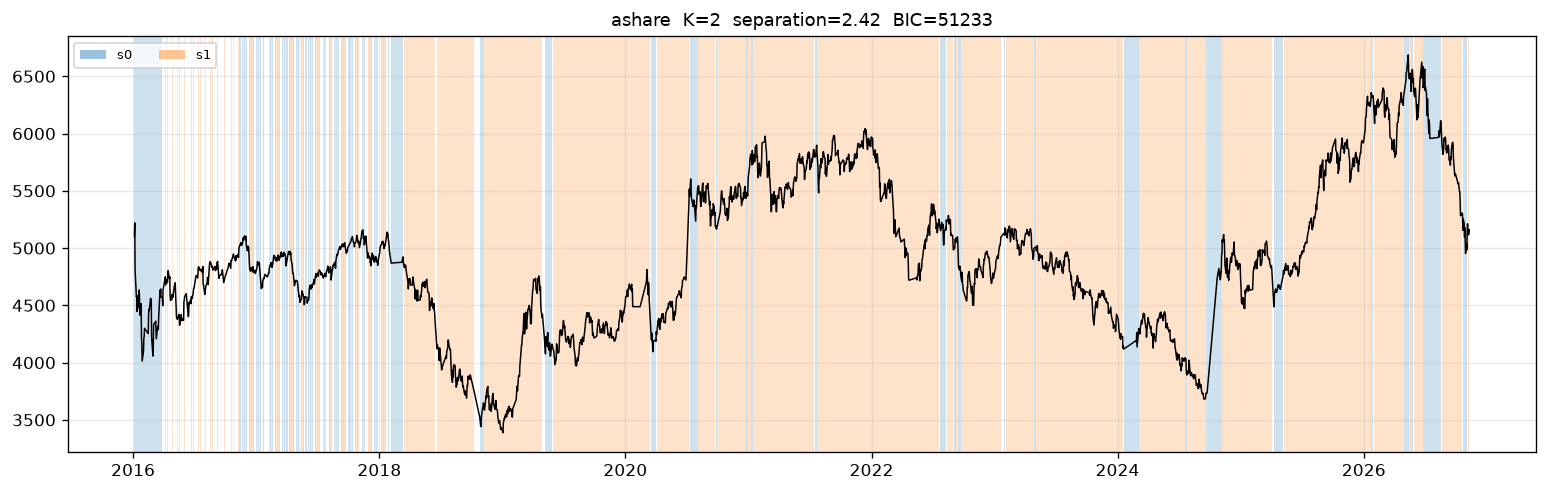

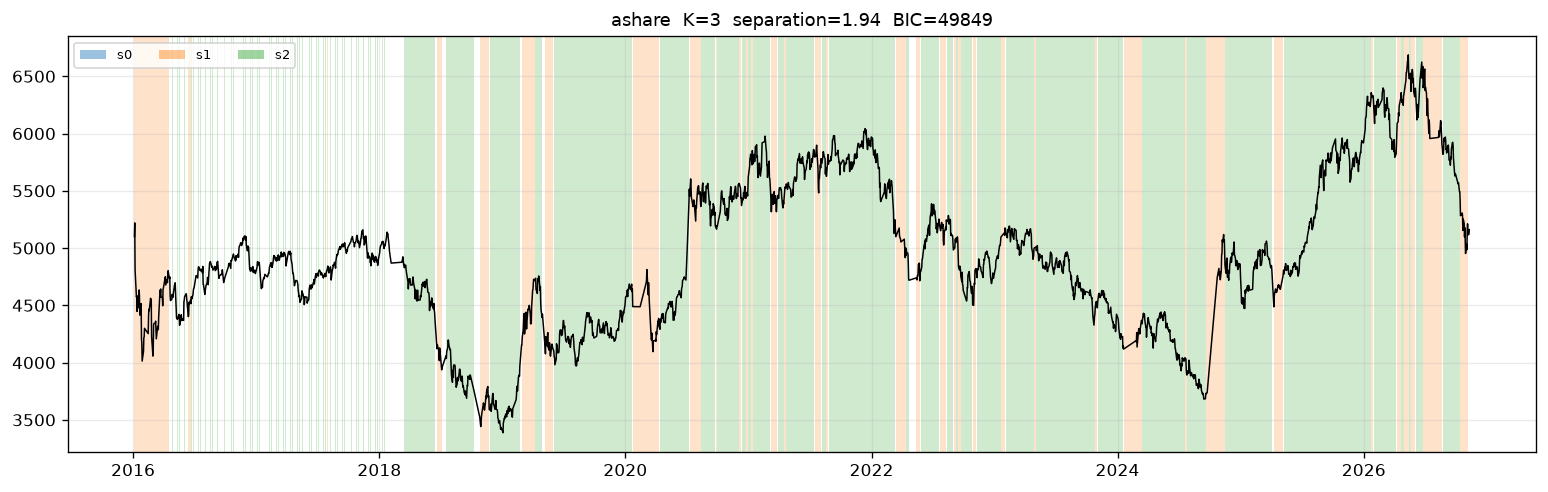

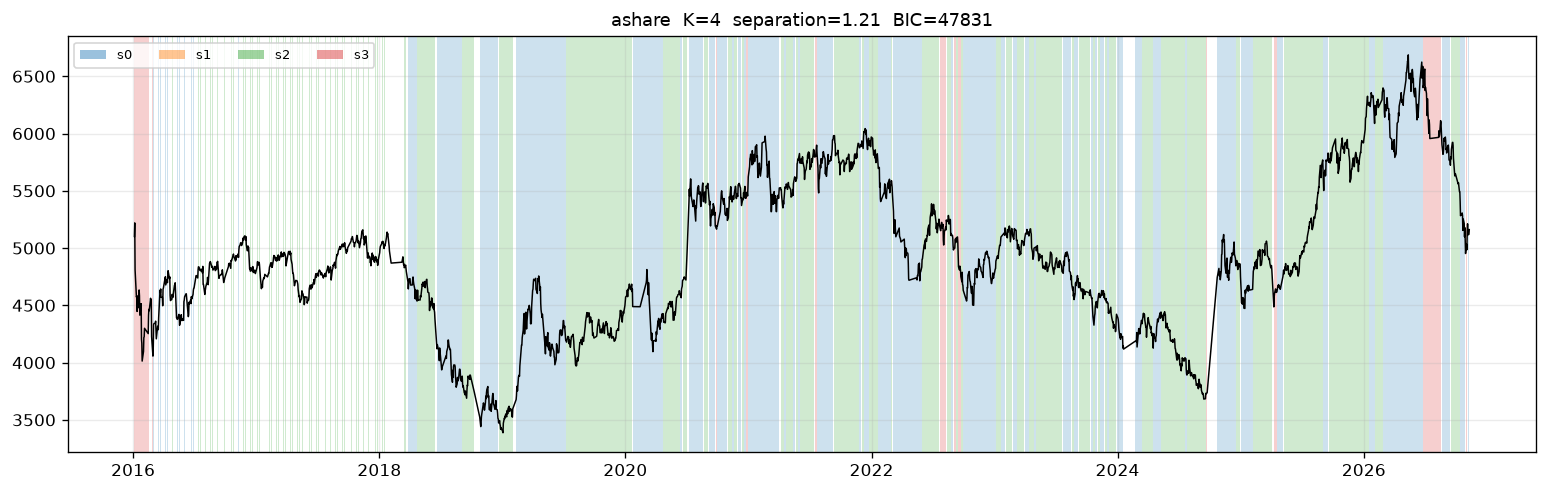

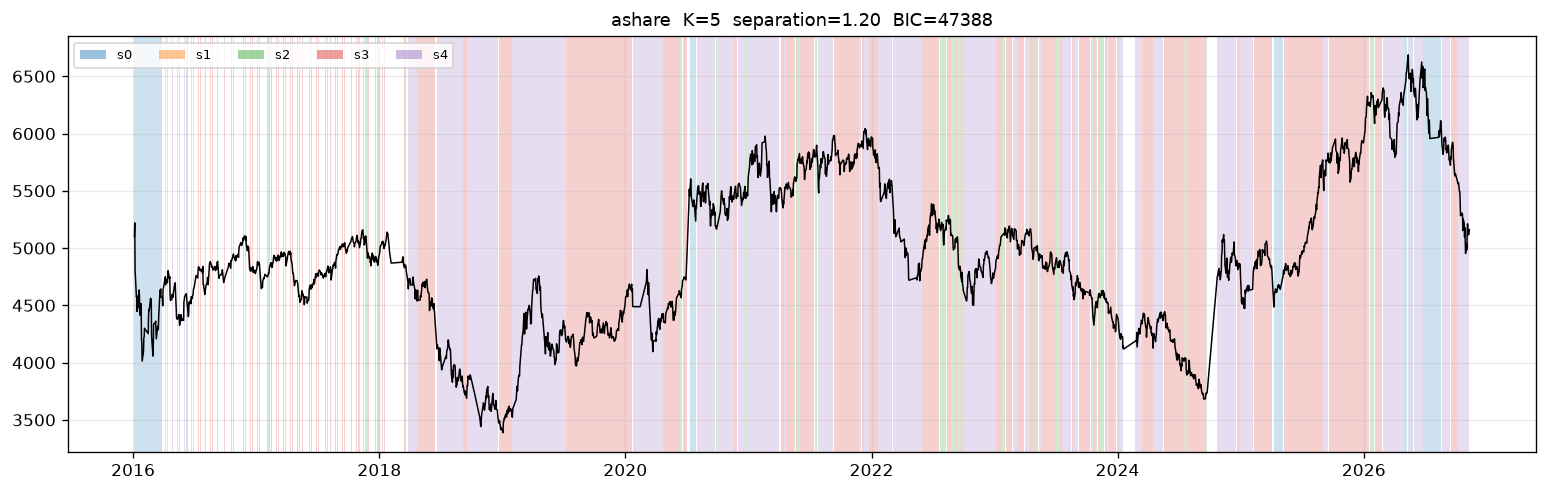

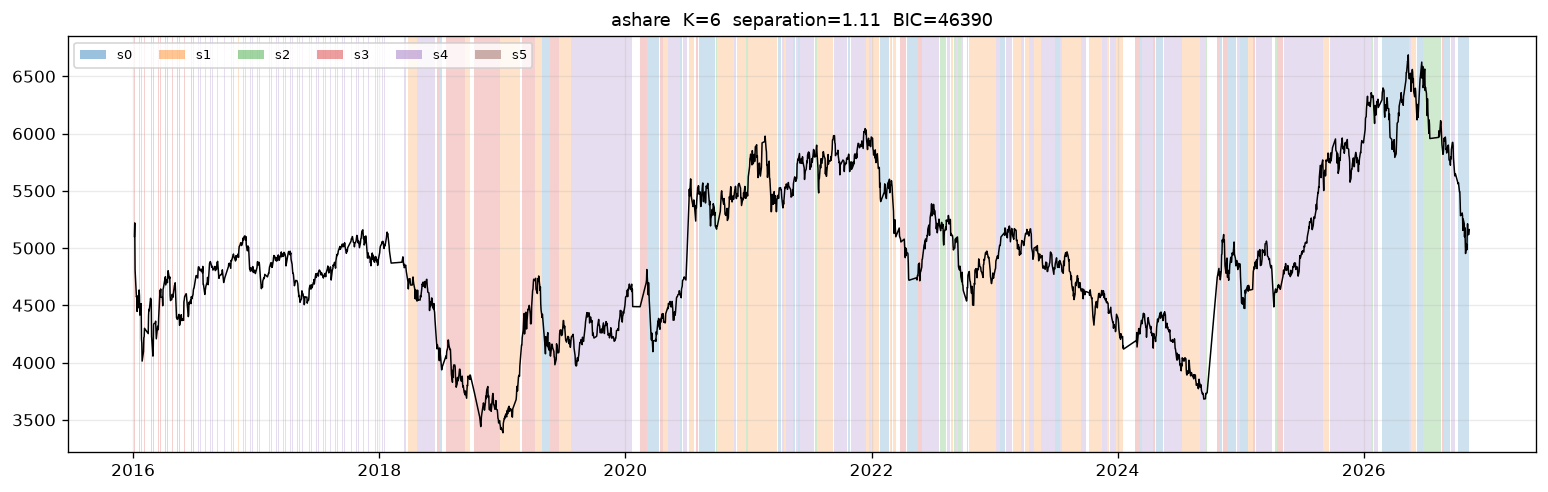

In [5]:
import matplotlib.pyplot as plt

for k in ks:
    fig = k_study.segment_figure(
        res[k], close.reindex(regular.index),
        f"ashare  K={k}  separation={res[k]['sep']['min']:.2f}  BIC={res[k]['bic']:.0f}")
    # fig.canvas.draw() 
    display(fig)
    plt.close(fig)

## 怎么读

- 碎块多 ⇒ 状态在追噪声
- 某状态天天只出现一两根 ⇒ 它是"异常点收纳盒"，没有市场含义
- 同一段行情里颜色反复跳 ⇒ 特征没抓住这段行情，不是 K 的问题
- 所有 K 都只按波动率分层 ⇒ 该换特征，不是调 K
